# Estatística Geral

## Testes de hipóteses


### Hipóteses estatísticas
Uma hipótese estatística é uma afirmação sobre um parâmetro da população.
Num teste, formulamos duas hipóteses complementares: se os dados levam a rejeitar uma, ficamos com a outra. A que contém a igualdade é chamada de hipótese nula; a outra, de hipótese alternativa.

#### Hipótese nula (denotada por H0):
É a hipótese que contém a igualdade (=, ≥ ou ≤). Para uma média, ela pode ter três formas:

$$H_0: \mu = \mu_0 \qquad H_0: \mu \ge \mu_0 \qquad H_0: \mu \le \mu_0$$

em que $\mu_0$ é o valor da média que se quer testar.

#### Hipótese alternativa (denotada por Ha) 
É o complemento da hipótese nula: vale quando H0 é falsa e contém uma desigualdade (<, ≠ ou >). Para uma média, ela assume uma destas três formas:

$$H_a: \mu \ne \mu_0 \qquad H_a: \mu < \mu_0 \qquad H_a: \mu > \mu_0$$

O quadro a seguir relaciona a afirmação feita sobre μ com as hipóteses correspondentes. O mesmo raciocínio vale para outros parâmetros, como p (proporção), σ (desvio padrão) ou σ² (variância).

| Afirmação sobre a média (e sua negação) | Hipóteses | Tipo de teste |
|---|---|---|
| É igual a $\mu_0$ (negação: é diferente de $\mu_0$) | $H_0: \mu = \mu_0$ e $H_a: \mu \ne \mu_0$ | bilateral |
| É maior ou igual a $\mu_0$ (negação: é menor que $\mu_0$) | $H_0: \mu \ge \mu_0$ e $H_a: \mu < \mu_0$ | unilateral à esquerda |
| É menor ou igual a $\mu_0$ (negação: é maior que $\mu_0$) | $H_0: \mu \le \mu_0$ e $H_a: \mu > \mu_0$ | unilateral à direita |

#### Exercício – Estabelecendo as hipóteses nula e alternativa
Estabeleça as hipóteses nula e alternativa:
- a) Uma escola afirma que 75% de seus alunos concluem o ensino médio no prazo.
    R: H0: p = 0,75 vs. Ha: p != 0,75 - Hipótese bilateral


- b) Um fabricante de lâmpadas LED afirma que o consumo médio de seu modelo é inferior a 9 W.
    H0: μ >= 9 vs. Ha: μ < 9 - Hipótese unilateral à esquerda


- c) Uma fábrica de parafusos afirma que a variância do comprimento de suas peças é de 0,04 mm².
    H0: σ² = 0,04 vs. Ha: σ² != 0,04 - Hipótese bilateral


- d) Uma empresa de entregas afirma que o tempo médio de entrega é de, no máximo, 40 minutos.
    H0: μ <= 40 vs. Ha: μ > 40 - Hipótese unilateral à direita


- e) Um aplicativo afirma que sua proporção de usuários ativos diariamente é superior a 30%.
    H0: p <= 0,30 vs. Ha: p > 0,30 - Hipótese unilateral à direita


- f) Uma padaria afirma que o desvio padrão do peso de seus pães é inferior a 5 gramas.
    H0: σ >= 5 vs. Ha: σ < 5 - Hipótese unilateral à esquerda

#### Tipos de erro
Todo teste começa supondo que a igualdade da hipótese nula é verdadeira, e só a abandona se os dados forem convincentes, de modo parecido com um julgamento em que o réu é considerado inocente até prova em contrário. Ao final, toma-se uma de duas decisões:
- 1) Rejeitar a hipótese nula
- 2) Aceitar (não rejeitar) a hipótese nula

Como a decisão se baseia em uma amostra, e não na população inteira, ela pode estar errada. As quatro combinações possíveis entre decisão e realidade são:

| Decisão | $H_0$ é verdadeira | $H_0$ é falsa |
|---|---|---|
| Aceitar $H_0$ | decisão correta (probabilidade $1 - \alpha$) | erro tipo II (probabilidade $\beta$) |
| Rejeitar $H_0$ | erro tipo I (probabilidade $\alpha$) | decisão correta (probabilidade $1 - \beta$) |

- Erro tipo I (denotada por α): Ocorre se a hipótese nula for rejeitada quando ela for realmente verdadeira.
- Erro tipo II (denotada por β): Ocorre se a hipótese nula não for rejeitada quando ela for realmente falsa.

O nível de significância α é a probabilidade de cometer o erro tipo I e é escolhido por quem faz o teste; já a probabilidade β do erro tipo II não é fixada diretamente. O ideal seria ter α = 0 e β = 0, mas isso é impossível: α, β e o tamanho da amostra n estão ligados, e fixando dois deles o terceiro fica determinado.

Na prática:

- 1. Com α fixo, aumentar n diminui β: uma amostra maior reduz a chance de aceitar H0 quando ela é falsa.
- 2. Com n fixo, diminuir α aumenta β, e vice-versa.
- 3. Para reduzir α e β ao mesmo tempo, é preciso aumentar o tamanho da amostra.

    O nível de significância (α) de um teste é a probabilidade de uma hipótese nula ser rejeitada, quando verdadeira.

#### Estatística de teste, região crítica e valor crítico
- Estatística de teste: valor calculado a partir da amostra e usado para decidir se H0 é rejeitada.
- Região crítica: conjunto dos valores da estatística de teste que levam à rejeição de H0.
- Valor crítico: valor (ou valores) que separa a região crítica dos demais valores. Ele depende da hipótese alternativa, da distribuição da estatística de teste e do nível de significância α.

A figura abaixo mostra como o valor crítico divide a distribuição amostral: estatísticas de teste à esquerda dele não levam à rejeição de $H_0$; à direita, na região crítica de área $\alpha$ (o nível de significância), rejeita-se $H_0$.

In [1]:
# Funções auxiliares usadas para desenhar as regiões críticas e os valores p deste notebook
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t


def regiao_critica(tipo, critico, rotulos, rotulo_alfa, dist=norm, titulo=None):
    """Curva com a região crítica sombreada.
    tipo: 'esquerda', 'direita' ou 'bilateral'; critico: valor crítico positivo;
    rotulos: textos dos valores críticos no eixo x (da esquerda para a direita)."""
    x_graf = np.linspace(-4, 4, 400)
    fig, ax = plt.subplots(figsize=(5.5, 3))
    ax.plot(x_graf, dist.pdf(x_graf), color="tab:blue")
    lados = {"esquerda": [-1], "direita": [1], "bilateral": [-1, 1]}[tipo]
    altura = dist.pdf(0)
    for lado in lados:
        cauda = np.linspace(critico, 4, 100) * lado
        ax.fill_between(cauda, dist.pdf(cauda), color="tab:red", alpha=0.35)
        ax.vlines(lado * critico, 0, altura * 0.55, color="k", lw=1)
        ax.annotate(rotulo_alfa, xy=(lado * (critico + 0.3), dist.pdf(critico) * 0.35),
                    xytext=(lado * 3.2, altura * 0.5), ha="center", fontsize=10,
                    arrowprops=dict(arrowstyle="->"))
        ax.text(lado * (critico + 0.9), -altura * 0.22, "Rejeitar $H_0$", ha="center", va="top", fontsize=9)
    centro = {"esquerda": 0.9, "direita": -0.9, "bilateral": 0}[tipo]
    ax.text(centro, -altura * 0.22, "Não rejeitar $H_0$", ha="center", va="top", fontsize=9)
    ax.set_xticks([lado * critico for lado in lados])
    ax.set_xticklabels(rotulos)
    ax.set_yticks([])
    ax.set_ylim(0, altura * 1.1)
    if titulo:
        ax.set_title(titulo, fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.show()


def desenhar_valor_p(ax, estat, tipo, dist=norm, rotulo=None):
    """Sombreia o valor p (área além da estatística de teste) num eixo."""
    x_graf = np.linspace(-4, 4, 400)
    ax.plot(x_graf, dist.pdf(x_graf), color="tab:blue")
    if tipo == "esquerda":
        caudas = [np.linspace(-4, estat, 100)]
    elif tipo == "direita":
        caudas = [np.linspace(estat, 4, 100)]
    else:
        caudas = [np.linspace(-4, -abs(estat), 100), np.linspace(abs(estat), 4, 100)]
    for cauda in caudas:
        ax.fill_between(cauda, dist.pdf(cauda), color="tab:orange", alpha=0.5)
    marcas = [estat] if tipo != "bilateral" else [-abs(estat), abs(estat)]
    ax.set_xticks(marcas)
    ax.set_xticklabels(rotulo if rotulo else [f"{m:g}".replace(".", ",") for m in marcas])
    ax.set_yticks([])
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right", "left"]].set_visible(False)

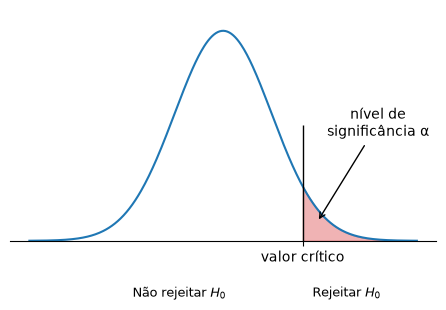

In [2]:
# O valor crítico separa a região de não rejeição da região crítica (área α)
regiao_critica("direita", 1.645, ["valor crítico"], "nível de\nsignificância α")

#### Testes unilaterais e bilaterais (Região crítica)
O tipo de desvio que nos interessa detectar define a hipótese alternativa. Pense em testar uma moeda com várias jogadas:

1. Se queremos saber apenas se a moeda é viciada, tanto caras demais quanto caras de menos chamam a atenção: Ha: p != 0,5, e olhamos as duas direções.
2. Se apostamos em caras, só nos preocupa a moeda dar caras de menos: Ha: p < 0,5, e olhamos uma direção só.

Assim, há três situações: desvios nas duas direções, desvios para baixo ou desvios para cima. Para uma proporção, elas correspondem às regiões críticas a seguir:

Teste unilateral à esquerda ($H_a: p < p_0$):

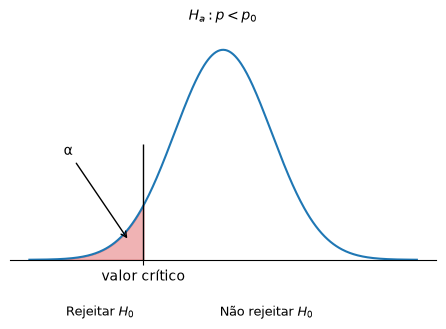

In [3]:
regiao_critica("esquerda", 1.645, ["valor crítico"], "α", titulo="$H_a: p < p_0$")

Teste unilateral à direita ($H_a: p > p_0$):

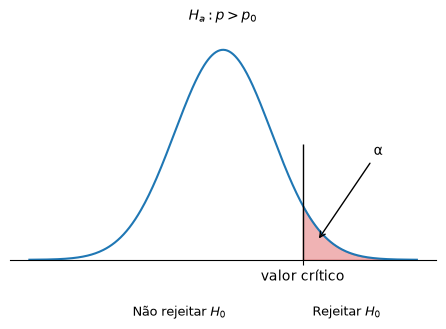

In [4]:
regiao_critica("direita", 1.645, ["valor crítico"], "α", titulo="$H_a: p > p_0$")

Teste bilateral ($H_a: p \ne p_0$):

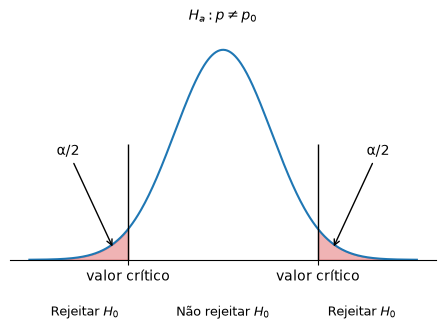

In [5]:
regiao_critica("bilateral", 1.96, ["valor crítico", "valor crítico"], "α/2", titulo="$H_a: p \\neq p_0$")

#### O método clássico de teste de hipóteses (Utilizando a região crítica)
- 1 - Escrever a hipótese nula (com a igualdade) e a alternativa.

- 2 - Fixar o nível de significância α, pensando em quão grave é um erro tipo I (0,05 e 0,01 são escolhas comuns).

- 3 - Escolher o teste adequado.

- 4 - Calcular a estatística de teste.

- 5 - Encontrar o(s) valor(es) crítico(s) e a região crítica.

- 6 - Rejeitar H0 se a estatística de teste cair na região crítica; caso contrário, não rejeitar H0.

- 7 - Traduzir a decisão em uma conclusão prática sobre o problema.

Os exemplos a seguir aplicam esses passos.

### Teste de hipóteses para uma média quando σ é conhecido (Teste z para uma amostra)
Este teste avalia afirmações sobre a média de uma população quando o desvio padrão populacional (σ) é conhecido.

Depois de escrever H0 e Ha e fixar α, calcula-se a estatística de teste:

$$z_{\text{teste}} = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}}$$

onde μ0 representa o valor da média que está sendo testado, σ representa o desvio padrão populacional, n é o tamanho da amostra e x̄ é a média da amostra.

A região crítica depende da hipótese alternativa e de α, como mostram as figuras:

$H_a: \mu < \mu_0$ (teste unilateral à esquerda):

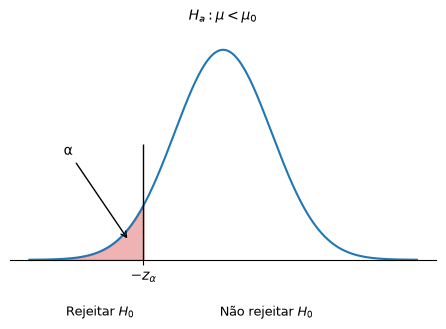

In [6]:
regiao_critica("esquerda", 1.645, ["$-z_{\\alpha}$"], "α", titulo="$H_a: \\mu < \\mu_0$")

$H_a: \mu \ne \mu_0$ (teste bilateral):

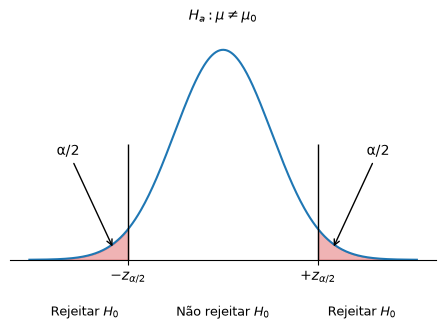

In [7]:
regiao_critica("bilateral", 1.96, ["$-z_{\\alpha/2}$", "$+z_{\\alpha/2}$"], "α/2", titulo="$H_a: \\mu \\neq \\mu_0$")

$H_a: \mu > \mu_0$ (teste unilateral à direita):

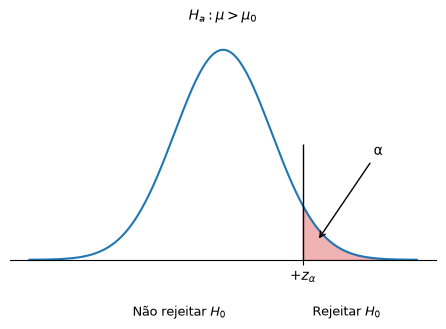

In [8]:
regiao_critica("direita", 1.645, ["$+z_{\\alpha}$"], "α", titulo="$H_a: \\mu > \\mu_0$")

Dessa forma, para o teste z para uma média, podemos estabelecer o seguinte critério de decisão:

| Hipótese alternativa | Rejeitar $H_0$ se | Não rejeitar $H_0$ se |
|---|---|---|
| $H_a: \mu < \mu_0$ | $z_{\text{teste}} \le -z_{\alpha}$ | $z_{\text{teste}} > -z_{\alpha}$ |
| $H_a: \mu > \mu_0$ | $z_{\text{teste}} \ge z_{\alpha}$ | $z_{\text{teste}} < z_{\alpha}$ |
| $H_a: \mu \ne \mu_0$ | $z_{\text{teste}} \le -z_{\alpha/2}$ ou $z_{\text{teste}} \ge z_{\alpha/2}$ | $-z_{\alpha/2} < z_{\text{teste}} < z_{\alpha/2}$ |

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [58]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"

In [65]:
#Realizando o teste de hipósteses para a Média.

import numpy as np


# Descrição das hipóteses:

H0 = "Média_<=_20"   #Hipótese nula (com igualdade)
Ha = "Média_>_20"   #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 50 #reclamações
Média_amostral = 29 #dias
Significância = 5 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 21 #Valor do desvio padrão populacional ou amostral


#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")

#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Verificação da hipótese nula
if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


Alfa:  0.05
Valor crítico:  1.64
Valor estudado:  20.0


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  3.0305
H0 rejeitada pois, Estatística de teste 3.0305 >= Valor crítico 1.64


#### Exercício
Uma marca de baterias de notebook afirma que elas suportam, em média, pelo menos 600 ciclos de carga. Numa amostra aleatória de 64 baterias, a média foi de 585 ciclos. Sabe-se que o desvio padrão populacional é de 48 ciclos. Use nível de significância de 0,03. O que você pode concluir?

R: H0: μ>=600 vs HA: μ<600
zteste= - 2,5
z0,03= -1,88
Como zteste< z0,03, deve-se rejeitar H0.
Conclusão: a duração média das baterias é inferior a 600 ciclos, contrariando a afirmação do fabricante, ao nível de 3% de significância.

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [58]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"

In [67]:
#Realizando o teste de hipósteses para a Média.

import numpy as np


# Descrição das hipóteses:

H0 = "Média_>=_600" #Hipótese nula (com igualdade)
Ha = "Média_<_600" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 64 #baterias
Média_amostral = 585 #ciclos
Significância = 3 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 48 #Valor do desvio padrão populacional ou amostral


#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")

#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Verificação da hipótese nula
if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


Alfa:  0.03
Valor crítico:  1.88
Valor estudado:  600.0


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  -2.5
H0 rejeitada pois, Estatística de teste -2.5 <= Valor crítico -1.88


### O método do valor p para o teste de hipóteses
Outra forma de decidir, muito usada em artigos e em programas estatísticos, é pelo valor p.
Dada uma hipótese nula e um conjunto de dados amostrais, o valor p é a probabilidade, supondo que a hipótese nula seja verdadeira, de se obter uma estatística de teste pelo menos tão extrema quanto a observada na amostra (no sentido da hipótese alternativa). Um valor p muito pequeno sugere que os resultados amostrais são muito improváveis sob a hipótese nula, ou seja, constitui evidência contra a hipótese nula.

O critério de decisão baseado no valor p é feito da seguinte maneira:
- Rejeitar a hipótese nula (H0) se o valor p é no máximo igual ao nível de significância (α).
- Não rejeitar a hipótese nula (H0) se o valor p é maior do que o nível de significância (α).

A tabela a seguir mostra como obter o valor p em cada tipo de teste.

| Tipo de teste | Como obter o valor p |
|---|---|
| Unilateral à direita | área à direita da estatística de teste |
| Bilateral | duas vezes a área à direita do valor absoluto da estatística de teste |
| Unilateral à esquerda | área à esquerda da estatística de teste |

Na figura abaixo, a área sombreada é o valor p em cada caso:

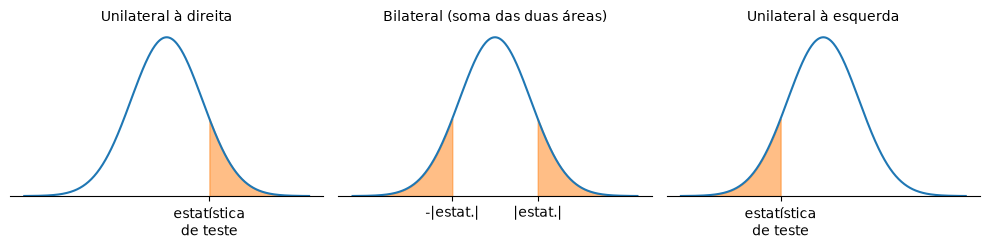

In [9]:
# Valor p (área sombreada) para cada tipo de teste, com uma estatística de teste ilustrativa
fig, eixos = plt.subplots(1, 3, figsize=(10, 2.6))
desenhar_valor_p(eixos[0], 1.2, "direita", rotulo=["estatística\nde teste"])
eixos[0].set_title("Unilateral à direita", fontsize=10)
desenhar_valor_p(eixos[1], 1.2, "bilateral", rotulo=["-|estat.|", "|estat.|"])
eixos[1].set_title("Bilateral (soma das duas áreas)", fontsize=10)
desenhar_valor_p(eixos[2], -1.2, "esquerda", rotulo=["estatística\nde teste"])
eixos[2].set_title("Unilateral à esquerda", fontsize=10)
plt.tight_layout()
plt.show()

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [82]:
#Realizando o teste de hipósteses para a Média.

import numpy as np


# Descrição das hipóteses:

H0 = "Média_<=_20"   #Hipótese nula (com igualdade)
Ha = "Média_>_20"   #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 50 #reclamações
Média_amostral = 29 #dias
Significância = 5 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 21 #Valor do desvio padrão populacional ou amostral


#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf) * 2
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de o valor-cp:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeictada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceita, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))

Alfa:  0.05
Valor crítico:  1.64
Valor estudado:  20.0


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  3.0305
P valor:  0.001221


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 rejeitada pois, Estatística de teste 3.0305 >= Valor crítico 1.64


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.001221 < Alfa 0.05


#### Exercício
- 1 - Para o exercício anterior, das baterias de notebook, obtenha a conclusão utilizando o valor p.

    R: H0: μ>=600 vs HA: μ<600
    zteste= - 2,5
    Valor p = 0,5-0,4938 = 0,0062
    Como valor p < 0,03, deve-se rejeitar H0.
    Conclusão: a duração média das baterias é inferior a 600 ciclos, contrariando a afirmação do fabricante, ao nível de 3% de significância.

In [86]:
#Realizando o teste de hipósteses para a Média.

import numpy as np


# Descrição das hipóteses:

H0 = "Média_>=_600" #Hipótese nula (com igualdade)
Ha = "Média_<_600" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 64 #baterias
Média_amostral = 585 #ciclos
Significância = 3 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 48 #Valor do desvio padrão populacional ou amostral


#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf) * 2
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de o valor-cp:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceita, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))

Alfa:  0.03
Valor crítico:  1.88
Valor estudado:  600.0


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  -2.5
P valor:  0.00621


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 rejeitada pois, Estatística de teste -2.5 <= Valor crítico -1.88


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.00621 < Alfa 0.03


#### Exercício
- 2 - Uma associação de moradores afirma que o gasto médio mensal das famílias do bairro com supermercado é superior a RS1200. Suponha que esse gasto seja normal, com desvio padrão σ = 300, conhecido de um estudo anterior. Numa amostra aleatória de 45 famílias, o gasto médio foi de RS1170. Há evidências que confirmem a afirmação da associação? Considere 2% de significância e use a região crítica e o valor p.

    R: H0: μ<=1200 vs HA: μ>1200
    zteste= -0,6708
    Valor p = 0,5+0,2486 = 0,7486
    Como valor p > 0,02, NÃO deve-se rejeitar H0.
    Conclusão: ao nível de 2% de significância, os dados não confirmam que o gasto médio seja superior a RS1200.

In [91]:
#Realizando o teste de hipósteses para a Média.

import numpy as np


# Descrição das hipóteses:

H0 = "Média_<=_1200" #Hipótese nula (com igualdade)
Ha = "Média_>_1200" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 45 #famílias
Média_amostral = 1170 #reais
Significância = 2 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 300 #Valor do desvio padrão populacional ou amostral


#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf) * 2
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de o valor-cp:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))

Alfa:  0.02
Valor crítico:  2.05
Valor estudado:  1200.0


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  -0.6708
P valor:  0.748826


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Estatística de teste -0.6708 < Valor crítico 2.05


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.748826 >= Alfa 0.02


### Teste de hipóteses (z) com intervalos de confiança
Um intervalo de confiança reúne os valores plausíveis para o parâmetro. Por isso, uma afirmação de que o parâmetro vale μ0 deve ser rejeitada quando μ0 fica fora do intervalo.

Como os intervalos que construímos são bilaterais, essa equivalência direta entre intervalo de confiança e teste só vale para testes bilaterais.

#### Exercício:
- 1 - Uma nutricionista afirma que os estudantes de uma faculdade dormem, em média, 7,2 horas por noite. Uma amostra aleatória de 40 estudantes teve média de 7,0 horas. Suponha que o desvio padrão seja σ = 0,9 hora e adote 4% de significância. O que se pode concluir? Use o valor p e o intervalo de confiança.

    R: H0: μ=7,2 vs HA: μ≠7,2
    zteste= -1,4055
    Pelo método do Valor p:
    Valor p = 2x(0,5-0,4207)=0,1586
    Como valor p > 0,04, NÃO deve-se rejeitar H0.

    Pelo método do intervalo de confiança (já que estamos em um teste bilateral):
    z=2,05
    E= 0,2917 hora
    I.C.= [6,7083 horas ; 7,2917 horas]
    Como o valor de μ0 = 7,2 está compreendido no intervalo de confiança, não deve-se rejeitar H0, o que confirma a conclusão obtida pelo método do valor p.

    Conclusão: ao nível de 4% de significância, os dados não contradizem a afirmação de que o sono médio dos estudantes é de 7,2 horas.

In [116]:
#Realizando o teste de hipósteses para a Média.

import numpy as np




# Descrição das hipóteses:

H0 = "Média_=_7.2" #Hipótese nula (com igualdade)
Ha = "Média_<>_7.2" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 40 #estudantes
Média_amostral = 7.0 #horas
Significância = 4 #% (alfa)
Desvio_populacional = True #O desvio conhecido é populacional?
Desvio_padrão = 0.9 #Valor do desvio padrão populacional ou amostral




#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
    P_valor = P_valor * 2
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_médias_amostrais = Desvio_padrão/(N_amostras**0.5)
        E = round(Valor_crítico * Desvio_médias_amostrais,4)
        if Valor_estudado > Média_amostral-E and Valor_estudado < Média_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))

Alfa:  0.04
Valor crítico:  2.05
Valor estudado:  7.2


Unilateral_esquerda:  False
Bilateral:  True
Unilateral_direita:  False


Estatística de teste:  -1.4055
P valor:  0.159873


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Valor crítico -2.05 < Estatística de teste -1.4055 < Valor crítico 2.05


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.159873 >= Alfa 0.04


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
H0 aceitada, pois o Valor estudado 7.2 está contido no intervalo de confiança I.C = [7.0-0.2917 ; 7.0+0.2917] ou seja, de 6.7083 a 7.2917


### Teste de hipóteses para uma média quando σ é desconhecido (Teste t-Student para uma amostra)
Assim como o teste z, o teste t avalia afirmações sobre uma média, mas é usado quando σ é desconhecido e a população é aproximadamente normal.
Sem σ, usamos o desvio padrão da amostra, s, no seu lugar. Em amostras grandes (n >= 30, como regra prática) a média amostral é aproximadamente normal e a diferença é pequena; em amostras menores, a distribuição correta para a estatística calculada com s é a t de Student.

Depois de escrever H0 e Ha e fixar α, a estatística de teste é:

$$t_{\text{teste}} = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$$

onde μ0 representa o valor da média que está sendo testado, s representa o desvio padrão da amostra (já que o desvio padrão da população é desconhecido), n é o tamanho da amostra e x̄ é a média da amostra.

A região crítica é definida como no teste z, mas com a distribuição t. O valor crítico vem da tabela t-Student, com:
- Graus de liberdade (g.l.) = n – 1.

Na linha dos graus de liberdade e na coluna da área de cauda desejada está o valor crítico. Se a região crítica estiver na cauda esquerda, o valor crítico é negativo.

#### Exemplo:
Num aplicativo de transporte, o tempo médio de espera por um carro era de 8 minutos. Depois de uma mudança no algoritmo de distribuição das corridas, uma amostra aleatória de 10 corridas teve tempo médio de espera de 7,1 minutos, com desvio padrão de 1,5 minuto. Ao nível de 5% de significância, houve alteração no tempo médio de espera? Suponha que a população seja aproximadamente normal.

Não conhecemos o desvio padrão populacional e a população é aproximadamente normal; portanto, usamos o teste t-Student:

Hipóteses: H0: μ = 8 versus Ha: μ ≠ 8.

Nível de significância: α = 0,05.

Graus de liberdade: n – 1 = 10 – 1 = 9.

Estatística de teste:

$$t_{\text{teste}} = \frac{7{,}1 - 8}{1{,}5 / \sqrt{10}} \approx -1{,}8974$$

Região crítica:

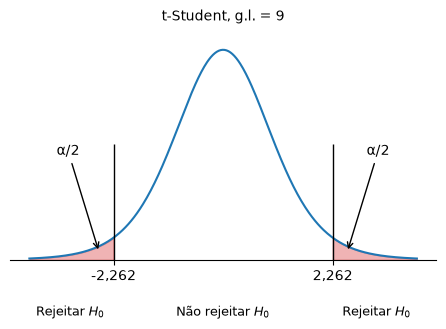

In [10]:
# Teste bilateral com 9 graus de liberdade e α = 0,05: valores críticos ±2,262
regiao_critica("bilateral", t.ppf(0.975, 9), ["-2,262", "2,262"], "α/2", dist=t(9),
               titulo="t-Student, g.l. = 9")

Valor crítico: t = 2,262

Na tabela t-Student, procura-se a linha de 9 graus de liberdade e a coluna de área $\alpha/2 = 0{,}025$ na cauda superior (usa-se $\alpha/2$ porque o teste é bilateral). A linha de 9 g.l., calculada com o `scipy` na célula abaixo:

| Área na cauda superior | 0,10 | 0,05 | 0,025 | 0,01 | 0,005 | 0,0025 | 0,001 | 0,0005 |
|---|---|---|---|---|---|---|---|---|
| $t$ (9 g.l.) | 1,383 | 1,833 | **2,262** | 2,821 | 3,250 | 3,690 | 4,297 | 4,781 |

In [11]:
# Linha de 9 graus de liberdade da tabela t-Student: valor t que deixa a área indicada na cauda superior
from scipy.stats import t

areas = [0.10, 0.05, 0.025, 0.01, 0.005, 0.0025, 0.001, 0.0005]
for area in areas:
    print(f"área {area}: t = {t.ppf(1 - area, 9):.3f}")

área 0.1: t = 1.383
área 0.05: t = 1.833
área 0.025: t = 2.262
área 0.01: t = 2.821
área 0.005: t = 3.250
área 0.0025: t = 3.690
área 0.001: t = 4.297
área 0.0005: t = 4.781


A estatística de teste (tteste ≈ -1,8974) está dentro do intervalo de -2,262 a 2,262, então não rejeitamos H0: não há evidência de que o tempo médio de espera tenha mudado.

Pelo método do valor p, como o teste é bilateral:

$$\text{valor p} = 2 \cdot P(T > \lvert t_{\text{teste}} \rvert) = 2 \cdot P(T > 1{,}8974)$$

Num teste bilateral usa-se o valor absoluto da estatística de teste e dobra-se a área da cauda direita (figura abaixo).

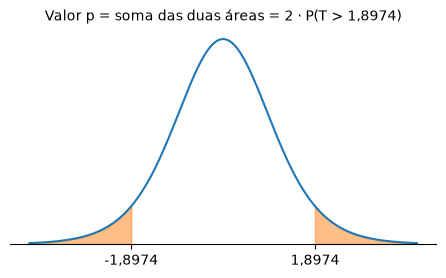

In [12]:
# Valor p bilateral: o dobro da área além de |t_teste| = 1,8974 (9 graus de liberdade)
fig, ax = plt.subplots(figsize=(5.5, 2.8))
desenhar_valor_p(ax, -1.8974, "bilateral", dist=t(9), rotulo=["-1,8974", "1,8974"])
ax.set_title("Valor p = soma das duas áreas = 2 · P(T > 1,8974)", fontsize=10)
plt.show()

Na tabela t-Student, na linha de n – 1 = 9 graus de liberdade, procura-se o valor mais próximo de |t_teste| = 1,8974:

Na linha de 9 g.l. (tabela acima), o valor mais próximo de 1,8974 é 1,833, na coluna 0,05. Assim, pela tabela, $P(T > 1{,}8974) \approx 0{,}05$; como 1,8974 fica entre 1,833 e 2,262, a área exata está entre 0,025 e 0,05. O cálculo com o `scipy` (célula abaixo) dá $P(T > 1{,}8974) \approx 0{,}0451$ e valor p $\approx 0{,}0903$: a conclusão é a mesma, pois o valor p é maior que $\alpha = 0{,}05$.

In [13]:
# Valor p exato para t_teste = -1,8974 com 9 graus de liberdade (teste bilateral)
from scipy.stats import t

cauda = t.sf(1.8974, 9)  # P(T > 1,8974)
print(f"P(T > 1,8974) = {cauda:.4f}".replace(".", ","))
print(f"valor p = 2 · P(T > 1,8974) = {2 * cauda:.4f}".replace(".", ","))

P(T > 1,8974) = 0,0451
valor p = 2 · P(T > 1,8974) = 0,0903


Pela tabela, o valor p é aproximadamente 2 x 0,05 = 0,10: se a hipótese nula fosse verdadeira, uma estatística de teste pelo menos tão extrema quanto a observada apareceria em cerca de 10% das amostras. Como esse valor é maior do que o nível de significância α = 0,05 = 5%, não rejeitamos a hipótese nula: os dados não mostram mudança no tempo médio de espera, que continua compatível com 8 minutos.

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [131]:
#Realizando o teste de hipósteses para a Média.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Média_=_8" #Hipótese nula (com igualdade)
Ha = "Média_<>_8" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 10 #corridas
Média_amostral = 7.1 #minutos
Significância = 5 #% (alfa)
Desvio_populacional = False #O desvio conhecido é populacional?
Desvio_padrão = 1.5 #Valor do desvio padrão populacional ou amostral




#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional and N_amostras >= 30:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))

    
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Desvio_populacional and N_amostras >= 30: # usando Z
    if Unilateral_esquerda:
        P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")
else: # usando T-Student
    if Unilateral_esquerda:
        P_valor, _ = quad(t.pdf, -np.inf, Estat_teste, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(t.pdf, Estat_teste, np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(t.pdf, abs(Estat_teste), np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_médias_amostrais = Desvio_padrão/(N_amostras**0.5)
        E = round(Valor_crítico * Desvio_médias_amostrais,4)
        if Valor_estudado > Média_amostral-E and Valor_estudado < Média_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))

Alfa:  0.05
Valor crítico:  2.262
Valor estudado:  8.0


Unilateral_esquerda:  False
Bilateral:  True
Unilateral_direita:  False


Estatística de teste:  -1.8974
P valor:  0.090262


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Valor crítico -2.262 < Estatística de teste -1.8974 < Valor crítico 2.262


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.090262 >= Alfa 0.05


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
H0 aceitada, pois o Valor estudado 8.0 está contido no intervalo de confiança I.C = [7.1-1.073 ; 7.1+1.073] ou seja, de 6.026999999999999 a 8.173


### Exercícios definitivos de teste de hipóteses para a Média

1. Uma corretora estima que o retorno médio anual dos fundos que administra é de 12%. Para avaliar uma nova estratégia de alocação, escolheu ao acaso 16 fundos geridos com a nova estratégia e obteve retorno médio de 14,1%, com desvio padrão de 3%. Supondo população aproximadamente normal, teste, ao nível de 1% de significância, se a nova estratégia aumenta o retorno médio.

    R: Hipótese unilateral à direita, tteste=2,8, valor p=0,0067

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [134]:
#Realizando o teste de hipósteses para a Média.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Média_<=_12" #Hipótese nula (com igualdade)
Ha = "Média_>_12" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 16 #fundos
Média_amostral = 14.1 #%
Significância = 1 #% (alfa)
Desvio_populacional = False #O desvio conhecido é populacional?
Desvio_padrão = 3 #Valor do desvio padrão populacional ou amostral




#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional and N_amostras >= 30:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Desvio_populacional and N_amostras >= 30: # usando Z
    if Unilateral_esquerda:
        P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")
else: # usando T-Student
    if Unilateral_esquerda:
        P_valor, _ = quad(t.pdf, -np.inf, Estat_teste, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(t.pdf, Estat_teste, np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(t.pdf, abs(Estat_teste), np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_médias_amostrais = Desvio_padrão/(N_amostras**0.5)
        E = round(Valor_crítico * Desvio_médias_amostrais,4)
        if Valor_estudado > Média_amostral-E and Valor_estudado < Média_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

H0:  Média_<=_12
Ha:  Média_>_12


Alfa:  0.01
Valor crítico:  2.602
Valor estudado:  12.0


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  2.8
P valor:  0.00673


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 rejeitada pois, Estatística de teste 2.8 >= Valor crítico 2.602


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.00673 < Alfa 0.01


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


2. Os tempos de resposta, em horas, de 8 chamados escolhidos ao acaso no sistema de suporte de uma empresa foram: 6 9 7 11 8 10 5 8. Ao nível de 5% de significância, podemos concluir que, em média, os chamados são respondidos em menos de 7 horas?

    R: Hipótese unilateral à esquerda, média da amostra=8, variância da amostra=4, desvio padrão da amostra=2, tteste=1,4142, valor p≈0,8999.

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [136]:
#Realizando o teste de hipósteses para a Média.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Média_>=_7" #Hipótese nula (com igualdade)
Ha = "Média_<_7" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

dados = [6, 9, 7, 11, 8, 10, 5, 8]

N_amostras = len(dados) #amostras
Média_amostral = np.mean(dados) #horas
Significância = 5 #% (alfa)
Desvio_populacional = False #O desvio conhecido é populacional?
Desvio_padrão = np.std(dados, ddof=1) #Valor do desvio padrão populacional ou amostral




#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional and N_amostras >= 30:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Desvio_populacional and N_amostras >= 30: # usando Z
    if Unilateral_esquerda:
        P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")
else: # usando T-Student
    if Unilateral_esquerda:
        P_valor, _ = quad(t.pdf, -np.inf, Estat_teste, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(t.pdf, Estat_teste, np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(t.pdf, abs(Estat_teste), np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_médias_amostrais = Desvio_padrão/(N_amostras**0.5)
        E = round(Valor_crítico * Desvio_médias_amostrais,4)
        if Valor_estudado > Média_amostral-E and Valor_estudado < Média_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

H0:  Média_>=_7
Ha:  Média_<_7


Alfa:  0.05
Valor crítico:  1.8946
Valor estudado:  7.0


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  1.4142
P valor:  0.899898


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Estatística de teste 1.4142 > Valor crítico -1.8946


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.899898 >= Alfa 0.05


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


### Teste de hipóteses para uma proporção
Esses testes servem para dados de contagem (quantos itens têm certa característica) e avaliam afirmações sobre a proporção de uma população. As suposições são:
- O experimento é binomial: número fixo de provas independentes, cada uma com dois resultados ("sucesso" e "fracasso") e a mesma probabilidade de sucesso.
- Valem n.p0 >= 5 e n.(1-p0) >= 5, de modo que a distribuição binomial pode ser aproximada por uma normal com $\mu = n \cdot p_0$ e $\sigma = \sqrt{n \cdot p_0 \cdot (1 - p_0)}$

Com essas suposições atendidas, o teste usa a distribuição normal padrão.
A notação que utilizaremos é a seguinte:

    n = tamanho da amostra;
    p̂ = x/n = proporção amostral;
    p0 = proporção populacional (usada nas hipóteses);
A estatística de teste é:

$$z_{\text{teste}} = \frac{\hat{p} - p_0}{\sqrt{\dfrac{p_0 (1 - p_0)}{n}}}$$

Na prática, o teste para uma proporção funciona como o teste z para uma média, pois usa a mesma distribuição: região crítica, valor crítico e valor p são obtidos da mesma maneira.

#### Exemplo:
Uma operadora de internet tinha, historicamente, 9% de atendimentos que eram reclamações. Depois de reformular a central de atendimento, uma amostra aleatória de 1000 atendimentos teve 68 reclamações. Ao nível de significância de 0,01, teste a afirmação de que a taxa de reclamações ficou abaixo de 9%.

A proporção amostral é p̂ = 68/1000 = 0,068 e a proporção de referência é 9% (0,09). Com α = 0,01, as hipóteses são:

H0: p >= 0,09
Ha: p < 0,09

As condições do teste são satisfeitas:

    n.p0 >= 5 -> 1000 x 0,09 = 90
    n.(1-p0) >= 5 -> 1000 x (1–0,09) = 910

A estatística de teste é:

$$z_{\text{teste}} = \frac{0{,}068 - 0{,}09}{\sqrt{\dfrac{0{,}09 \cdot (1 - 0{,}09)}{1000}}} \approx -2{,}43$$

Região crítica:
O valor crítico é o z que deixa área 0,49 entre 0 e z na tabela da normal, ou seja, z = 2,33 (no lado esquerdo, -2,33). Como a estatística de teste (-2,43) é menor do que -2,33, rejeitamos a hipótese nula.

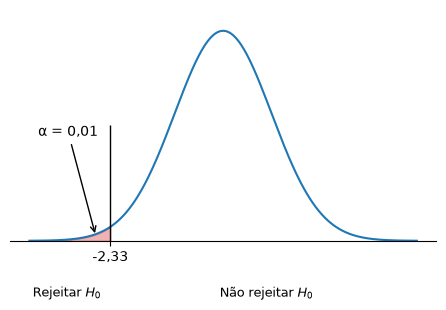

In [14]:
# Teste unilateral à esquerda com α = 0,01: valor crítico -2,33
regiao_critica("esquerda", 2.33, ["-2,33"], "α = 0,01")

Valor p:
O valor p é a área da normal padrão abaixo de -2,43: 0,5 – 0,4925 = 0,0075. Interpretando: se a taxa de reclamações ainda fosse 9% (H0 verdadeira), a probabilidade de obter uma proporção amostral tão baixa quanto a observada, ou menor, seria de apenas 0,0075. Como 0,0075 é menor do que o nível de significância (0,01), rejeitamos H0.

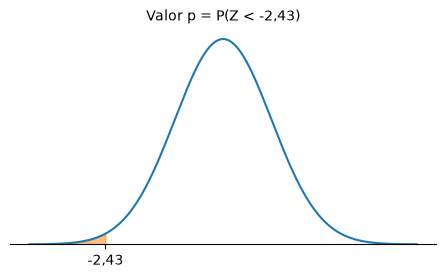

In [15]:
# Valor p: área à esquerda da estatística de teste (-2,43)
fig, ax = plt.subplots(figsize=(5.5, 2.8))
desenhar_valor_p(ax, -2.43, "esquerda", rotulo=["-2,43"])
ax.set_title("Valor p = P(Z < -2,43)", fontsize=10)
plt.show()

Conclusão: há evidência suficiente, ao nível de 1%, de que a taxa de reclamações ficou abaixo de 9% depois da mudança.

Em testes bilaterais também se pode decidir pelo intervalo de confiança:

$$\hat{p} \pm z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$

Rejeita-se a afirmação de que o parâmetro vale p0 quando p0 fica fora do intervalo.

Resolvendo o exemplo:

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [137]:
#Realizando o teste de hipósteses para a Proporção.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Proporção_>=_0.09" #Hipótese nula (com igualdade)
Ha = "Proporção_<_0.09" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 1000 #atendimentos
Ocorrências = 68 #reclamações
Prop_amostral = Ocorrências/N_amostras #proporção
Significância = 1 #% (alfa)



#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Verificação das suposições para a Proporção
if (N_amostras * Valor_estudado >= 5) and (N_amostras * (1-Valor_estudado) >= 5):
    print ("Suposições satifeitas (OK) para aproximação da distribuição por uma normal.")
    print("\n")
else:
    print ("Suposições não satifeitas (NOK) para aproximação da distribuição por uma normal.")
    print("\n")

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Prop_amostral-Valor_estudado)/(((Valor_estudado*(1-Valor_estudado))/N_amostras)**0.5),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
    P_valor = round(P_valor, 6)
    P_valor = P_valor * 2
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")



#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5
        E = round(Valor_crítico * Desvio_prop_amostrais,4)
        if Valor_estudado > Prop_amostral-E and Valor_estudado < Prop_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

Suposições satifeitas (OK) para aproximação da distribuição por uma normal.


H0:  Proporção_>=_0.09
Ha:  Proporção_<_0.09


Alfa:  0.01
Valor crítico:  2.33
Valor estudado:  0.09


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  -2.431
P valor:  0.007529


Conclusão de acordo com a relação da estatística de teste e a região crítica:


H0 rejeitada pois, Estatística de teste -2.431 <= Valor crítico -2.33


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.007529 < Alfa 0.01


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


### Exercícios definitivos de teste de hipóteses para a Proporção

1. Uma clínica tinha taxa de 12% de faltas às consultas agendadas. Ela passou a enviar lembretes por mensagem no dia anterior e, numa amostra aleatória de 1500 consultas com o novo sistema, houve 162 faltas. Teste a afirmação de que a taxa de faltas diminuiu com os lembretes, ao nível de 2% de significância. O novo sistema parece eficaz?

    R: Hipótese unilateral à esquerda
    p̂ =0,108
    zteste= -1,4302
    valor p = 0,5-0,4236 = 0,0764 > α -> NÃO rejeito a hipótese nula

In [48]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [85]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [138]:
#Realizando o teste de hipósteses para a Proporção.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Proporção_>=_0.12" #Hipótese nula (com igualdade)
Ha = "Proporção_<_0.12" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 1500 #consultas
Ocorrências = 162 #faltas
Prop_amostral = Ocorrências/N_amostras #proporção
Significância = 2 #% (alfa)



#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Verificação das suposições para a Proporção
if (N_amostras * Valor_estudado >= 5) and (N_amostras * (1-Valor_estudado) >= 5):
    print ("Suposições satifeitas (OK) para aproximação da distribuição por uma normal.")
    print("\n")
else:
    print ("Suposições não satifeitas (NOK) para aproximação da distribuição por uma normal.")
    print("\n")

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Prop_amostral-Valor_estudado)/(((Valor_estudado*(1-Valor_estudado))/N_amostras)**0.5),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
    P_valor = round(P_valor, 6)
    P_valor = P_valor * 2
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")



#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5
        E = round(Valor_crítico * Desvio_prop_amostrais,4)
        if Valor_estudado > Prop_amostral-E and Valor_estudado < Prop_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

Suposições satifeitas (OK) para aproximação da distribuição por uma normal.


H0:  Proporção_>=_0.12
Ha:  Proporção_<_0.12


Alfa:  0.02
Valor crítico:  2.05
Valor estudado:  0.12


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  -1.4302
P valor:  0.07633


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Estatística de teste -1.4302 > Valor crítico -2.05


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.07633 >= Alfa 0.02


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


2. Num programa de reeducação alimentar, 80 participantes foram acompanhados por um ano; 34 deles mantiveram o peso perdido e os demais o recuperaram. Ao nível de 0,10 de significância, teste a afirmação de que no máximo 30% dos participantes recuperam o peso em um ano. Os resultados sugerem que o programa é menos eficaz do que se afirma?

    R: Hipótese unilateral à direita
    p̂ =0,575
    zteste= 5,3675
    valor p < 0,0002 (z está além do fim da tabela; o valor exato é cerca de 4 x 10^-8) < α -> Rejeito a hipótese nula

In [11]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [12]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [13]:
#Realizando o teste de hipósteses para a Proporção.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Proporção_<=_0.30" #Hipótese nula (com igualdade)
Ha = "Proporção_>_0.30" #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 80 #participantes
Ocorrências = (80-34) #recuperaram o peso
Prop_amostral = Ocorrências/N_amostras #proporção
Significância = 10 #% (alfa)



#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Verificação das suposições para a Proporção
if (N_amostras * Valor_estudado >= 5) and (N_amostras * (1-Valor_estudado) >= 5):
    print ("Suposições satifeitas (OK) para aproximação da distribuição por uma normal.")
    print("\n")
else:
    print ("Suposições não satifeitas (NOK) para aproximação da distribuição por uma normal.")
    print("\n")

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Prop_amostral-Valor_estudado)/(((Valor_estudado*(1-Valor_estudado))/N_amostras)**0.5),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
    P_valor = round(P_valor, 6)
    P_valor = P_valor * 2
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")



#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5
        E = round(Valor_crítico * Desvio_prop_amostrais,4)
        if Valor_estudado > Prop_amostral-E and Valor_estudado < Prop_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

Suposições satifeitas (OK) para aproximação da distribuição por uma normal.


H0:  Proporção_<=_0.30
Ha:  Proporção_>_0.30


Alfa:  0.1
Valor crítico:  1.28
Valor estudado:  0.3


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  5.3675
P valor:  0.0


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 rejeitada pois, Estatística de teste 5.3675 >= Valor crítico 1.28


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.0 < Alfa 0.1


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


In [15]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [16]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]




# Definindo o tipo de região crítica de acordo com a hipótese alternativa.

import re

def Def_Tipo_Região(Significância, Ha):
    term = re.search('.*?_([<|>].?)_', Ha)

    if term.group(1) == "<":
        Unilateral_esquerda = True
        Bilateral = False
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == "<>":
        Unilateral_esquerda = False
        Bilateral = True
        Unilateral_direita = False
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    elif term.group(1) == ">":
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = True
        return Unilateral_esquerda, Bilateral, Unilateral_direita
    else:
        Unilateral_esquerda = False
        Bilateral = False
        Unilateral_direita = False
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return Unilateral_esquerda, Bilateral, Unilateral_direita
        
        
#Definindo valor de estudo do teste
def Def_Valor_estudo(Significância, Ha):
    Valor_estudado_temp = re.search('.*_(.*)', Ha)
    return float(Valor_estudado_temp.group(1))


#Definindo o valor passado para cálculo do valor crítico (z)
        
def Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa):

    if Unilateral_esquerda or Unilateral_direita:
        return (((1-Alfa)-(Alfa))*100)
    elif Bilateral:
        return (((1-Alfa)*100))
    else:
        print("ERROR: Operação de desigualdade não reconhecida em 'Ha'")
        return "ERROR"
    
    
#Definindo a função Normal padrão.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

In [20]:
#Realizando o teste de hipósteses para a Média.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Média_>=_2500"   #Hipótese nula (com igualdade)
Ha = "Média_<_2500"   #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 12 #casos
Média_amostral = 2500.9 #
Significância = 2.5 #% (alfa)
Variância = 1008.4
Desvio_populacional = False #O desvio conhecido é populacional?
Desvio_padrão = Variância**0.5 #Valor do desvio padrão populacional ou amostral




#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100


#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
if Desvio_populacional and N_amostras >= 30:
    Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))
else:
    Valor_crítico = T(N_amostras, Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Média_amostral-Valor_estudado)/(Desvio_padrão/(N_amostras**0.5)),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Desvio_populacional and N_amostras >= 10: # usando Z
    if Unilateral_esquerda:
        P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")
else: # usando T-Student
    if Unilateral_esquerda:
        P_valor, _ = quad(t.pdf, -np.inf, Estat_teste, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Unilateral_direita:
        P_valor, _ = quad(t.pdf, Estat_teste, np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        print("P valor: ",P_valor)
    elif Bilateral:
        P_valor, _ = quad(t.pdf, abs(Estat_teste), np.inf, args=(N_amostras-1))
        P_valor = round(P_valor, 6)
        P_valor = P_valor * 2
        print("P valor: ",P_valor)
    else:
        print("ERRO: Sem o tipo de teste para cálculo do valor P")


#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_médias_amostrais = Desvio_padrão/(N_amostras**0.5)
        E = round(Valor_crítico * Desvio_médias_amostrais,4)
        if Valor_estudado > Média_amostral-E and Valor_estudado < Média_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Média_amostral, E, Valor_estudado, Média_amostral-E, Média_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

H0:  Média_>=_2500
Ha:  Média_<_2500


Alfa:  0.025
Valor crítico:  2.201
Valor estudado:  2500.0


Unilateral_esquerda:  True
Bilateral:  False
Unilateral_direita:  False


Estatística de teste:  0.0982
P valor:  0.53823


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 aceitada pois, Estatística de teste 0.0982 > Valor crítico -2.201


Conclusão de acordo com a relação do valor-p e a significância:
H0 aceitada, pois P-valor 0.53823 >= Alfa 0.025


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.


In [9]:
#Realizando o teste de hipósteses para a Proporção.

import numpy as np
from scipy.stats import t



# Descrição das hipóteses:

H0 = "Proporção_<=_0.05"   #Hipótese nula (com igualdade)
Ha = "Proporção_>_0.05"   #Hipótese alternativa (sem igualdade)


#Variáveis do enunciado:

N_amostras = 100 #fumantes
Ocorrências = 10 #não fumaram
Prop_amostral = Ocorrências/N_amostras #proporção
Significância = 5 #% (alfa)



#Cálculos de variáveis secundárias
Unilateral_esquerda, Bilateral, Unilateral_direita = Def_Tipo_Região(Significância, Ha)
Valor_estudado = Def_Valor_estudo(Significância, Ha)
Alfa = Significância/100

#Verificação das suposições para a Proporção
if (N_amostras * Valor_estudado >= 5) and (N_amostras * (1-Valor_estudado) >= 5):
    print ("Suposições satifeitas (OK) para aproximação da distribuição por uma normal.")
    print("\n")
else:
    print ("Suposições não satifeitas (NOK) para aproximação da distribuição por uma normal.")
    print("\n")

#Cálculo do valor crítico com desvio populacional conhecido ou desconhecido
Valor_crítico = Z(Def_Valor_Crítico(Unilateral_esquerda, Bilateral, Unilateral_direita, Alfa))


print("H0: ",H0)
print("Ha: ",Ha)
print("\n")
print("Alfa: ",Alfa)
print("Valor crítico: ",Valor_crítico)
print("Valor estudado: ",Valor_estudado)
print("\n")
print("Unilateral_esquerda: ",Unilateral_esquerda)
print("Bilateral: ",Bilateral)
print("Unilateral_direita: ",Unilateral_direita)
print("\n")


#Cálculo da estatística de teste
Estat_teste = round((Prop_amostral-Valor_estudado)/(((Valor_estudado*(1-Valor_estudado))/N_amostras)**0.5),4)
print("Estatística de teste: ",Estat_teste)


#Cálculo o valor-p
if Unilateral_esquerda:
    P_valor, _ = quad(F_Normal_Padrao, -np.inf, Estat_teste)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Unilateral_direita:
    P_valor, _ = quad(F_Normal_Padrao, Estat_teste, np.inf)
    P_valor = round(P_valor, 6)
    print("P valor: ",P_valor)
elif Bilateral:
    P_valor, _ = quad(F_Normal_Padrao, abs(Estat_teste), np.inf)
    P_valor = round(P_valor, 6)
    P_valor = P_valor * 2
    print("P valor: ",P_valor)
else:
    print("ERRO: Sem o tipo de teste para cálculo do valor P")



#Verificação da hipótese nula de acordo com a estatística de teste:
print("\n")
print("Conclusão de acordo com a relação da estatística de teste e a região crítica:")

if Unilateral_esquerda:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} > Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
elif Unilateral_direita:
    if Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))
elif Bilateral:
    if Estat_teste <= -Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} <= Valor crítico -{1}" .format(Estat_teste, Valor_crítico))
    elif Estat_teste >= Valor_crítico:
        print("H0 rejeitada pois, Estatística de teste {0} >= Valor crítico {1}" .format(Estat_teste, Valor_crítico))
    else:
        print("H0 aceitada pois, Valor crítico -{1} < Estatística de teste {0} < Valor crítico {1}" .format(Estat_teste, Valor_crítico))


#Verificação da hipótese nula de acordo com o valor-p:       
print("\n")
print("Conclusão de acordo com a relação do valor-p e a significância:")

if P_valor < Alfa:
    print("H0 rejeitada, pois P-valor {0} < Alfa {1}" .format(P_valor, Alfa))
else:
    print("H0 aceitada, pois P-valor {0} >= Alfa {1}" .format(P_valor, Alfa))
    
    
#Verificação da hipótese nula de acordo com Intervalo de confiança (em caso de teste Bilateral):
print("\n")
print("Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:")

if Bilateral:
        Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5
        E = round(Valor_crítico * Desvio_prop_amostrais,4)
        if Valor_estudado > Prop_amostral-E and Valor_estudado < Prop_amostral+E:
            print("H0 aceitada, pois o Valor estudado {2} está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
        else:
            print("H0 rejeitada, pois o Valor estudado {2} não está contido no intervalo de confiança I.C = [{0}-{1} ; {0}+{1}] ou seja, de {3} a {4}" .format(Prop_amostral, E, Valor_estudado, Prop_amostral-E, Prop_amostral+E))
else:
    print("Teste não bilateral, portanto inviável análise através de I.C.")

Suposições satifeitas (OK) para aproximação da distribuição por uma normal.


H0:  Proporção_<=_0.05
Ha:  Proporção_>_0.05


Alfa:  0.05
Valor crítico:  1.64
Valor estudado:  0.05


Unilateral_esquerda:  False
Bilateral:  False
Unilateral_direita:  True


Estatística de teste:  2.2942
P valor:  0.01089


Conclusão de acordo com a relação da estatística de teste e a região crítica:
H0 rejeitada pois, Estatística de teste 2.2942 >= Valor crítico 1.64


Conclusão de acordo com a relação do valor-p e a significância:
H0 rejeitada, pois P-valor 0.01089 < Alfa 0.05


Conclusão de acordo com a relação do valor estudado e o intervalo de confiança:
Teste não bilateral, portanto inviável análise através de I.C.
